# Dimension reduction with PCA

**Goal:** Compress many features into a few components and visualise high-dimensional data.

**Data:** Pima Indians Diabetes dataset (8 features); Iris dataset.

**Methods:** PCA to 2 and 3 components, 2D and interactive 3D (Plotly) visualisation coloured by outcome, standardisation, cumulative explained variance, Incremental PCA.

**Takeaway:** without scaling, PCA is dominated by the features with the largest numeric range (e.g. insulin, glucose). After standardisation, the explained-variance curve shows how many components are needed to keep most of the information.

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris # loading data which is embeded in Sklearn as example
import sklearn.decomposition as sd # importing the functions of dimension reduction ( sub_library)

In [ ]:
data = pd.read_csv('/content/diabetes.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               767 non-null    int64  
 1   Glucose                   767 non-null    int64  
 2   BloodPressure             767 non-null    int64  
 3   SkinThickness             767 non-null    int64  
 4   Insulin                   767 non-null    int64  
 5   BMI                       767 non-null    float64
 6   DiabetesPedigreeFunction  767 non-null    float64
 7   Age                       767 non-null    int64  
 8   Outcome                   767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
X = data[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y = data['Outcome'].to_numpy()

In [ ]:
# Apply PCA to reduce the dataset to 2 dimensions ( variables)
pca = sd.PCA(n_components=2) # creat model which means you decide the function ( PCA) and the number of components

X_reduced = pca.fit_transform(X) #Result: X_reduced is the transformed dataset with only 2 features (principal components).

In [ ]:
X_reduced

array([[-75.82558031,  35.91770202],
       [-82.45757272, -28.94429304],
       [-74.75046986,  67.85562834],
       ...,
       [-78.74672732,   7.65501433],
       [ 32.00808087,  -3.39769587],
       [-80.32584756,  14.12874289]])

In [ ]:
y

array([1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1,

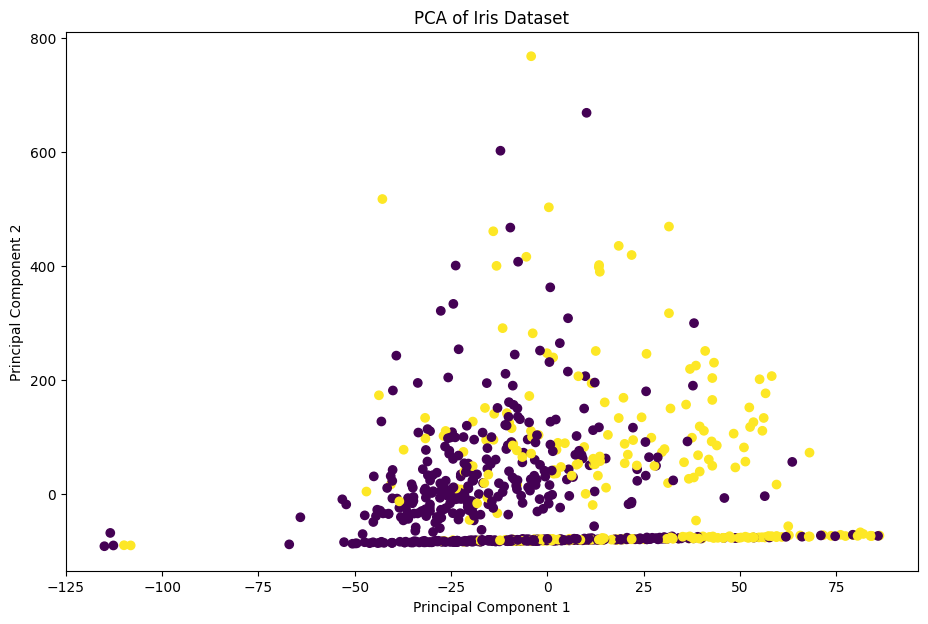

In [ ]:
# Plot the reduced dataset
plt.figure(figsize=(11, 7))
plt.scatter(X_reduced[:, 1], X_reduced[:, 0], c=y)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Iris Dataset')
#plt.legend(labels=data.target_names)
plt.show()

In [ ]:
import pandas as pd

# Create a DataFrame with the original data
df = pd.DataFrame(X, columns=X.columns)

# Add a column for the target variable
df['target'] = y

# Add columns for the reduced data
df['PC1'] = X_reduced[:,0]
df['PC2'] = X_reduced[:, 1]

# Print the DataFrame

df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,target,PC1,PC2
0,6,148,72,35,0,33.6,0.627,50,1,-75.825580,35.917702
1,1,85,66,29,0,26.6,0.351,31,0,-82.457573,-28.944293
2,8,183,64,0,0,23.3,0.672,32,1,-74.750470,67.855628
3,1,89,66,23,94,28.1,0.167,21,0,10.978342,-34.922335
4,0,137,40,35,168,43.1,2.288,33,1,89.637178,2.732307
...,...,...,...,...,...,...,...,...,...,...,...
762,9,89,62,0,0,22.5,0.142,33,0,-83.978203,-23.695917
763,10,101,76,48,180,32.9,0.171,63,0,99.136948,-25.085979
764,2,122,70,27,0,36.8,0.340,27,0,-78.746727,7.655014
765,5,121,72,23,112,26.2,0.245,30,0,32.008081,-3.397696


In [ ]:
# Apply PCA to reduce the dataset to 3 dimensions
pca = sd.PCA(n_components=3)
X_reduced = pca.fit_transform(X) #Result: X_reduced is the transformed dataset with 3 feautures (principal components).
df = pd.DataFrame(X, columns=X.columns)

# Add a column for the target variable
df['target'] = y

# Add columns for the reduced data
df['PC1'] = X_reduced[:, 0]
df['PC2'] = X_reduced[:, 1]
df['PC3'] = X_reduced[:, 2]
df


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,target,PC1,PC2,PC3
0,6,148,72,35,0,33.6,0.627,50,1,-75.825580,35.917702,7.251928
1,1,85,66,29,0,26.6,0.351,31,0,-82.457573,-28.944293,5.518156
2,8,183,64,0,0,23.3,0.672,32,1,-74.750470,67.855628,-19.473211
3,1,89,66,23,94,28.1,0.167,21,0,10.978342,-34.922335,0.075008
4,0,137,40,35,168,43.1,2.288,33,1,89.637178,2.732307,-25.221450
...,...,...,...,...,...,...,...,...,...,...,...,...
762,9,89,62,0,0,22.5,0.142,33,0,-83.978203,-23.695917,-7.743871
763,10,101,76,48,180,32.9,0.171,63,0,99.136948,-25.085979,19.552525
764,2,122,70,27,0,36.8,0.340,27,0,-78.746727,7.655014,4.138650
765,5,121,72,23,112,26.2,0.245,30,0,32.008081,-3.397696,1.597363


In [ ]:
# how to visulaze 3d dataframe

import plotly.express as px

fig = px.scatter_3d(df, x="PC1", y="PC2", z="PC3", color="target")
fig.show()


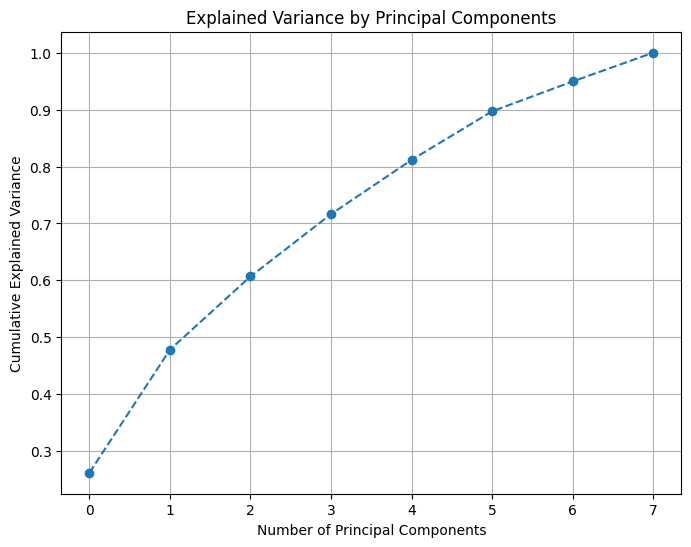

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# Standardize the features
scaler = StandardScaler() # define model
X_scaled = scaler.fit_transform(X) # this is the function to show the explanation-power of the new set of the components in comparison to the original number of the variables

pca_full = PCA().fit(X_scaled)
plt.figure(figsize=(8, 6))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker='o', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by Principal Components')
plt.grid()
plt.show()


In [ ]:
X_scaled

array([[ 0.63872696,  0.8470548 ,  0.14960376, ...,  0.20362197,
         0.467638  ,  1.42463671],
       [-0.84582934, -1.124361  , -0.16038116, ..., -0.6842578 ,
        -0.36549383, -0.19177802],
       [ 1.23254948,  1.9422858 , -0.26370947, ..., -1.10282969,
         0.60347471, -0.10670356],
       ...,
       [-0.54891808,  0.03345463,  0.04627545, ...,  0.60950986,
        -0.39869836, -0.53207586],
       [ 0.3418157 ,  0.00216231,  0.14960376, ..., -0.73499379,
        -0.68546474, -0.27685248],
       [-0.84582934,  0.15862388, -0.47036608, ..., -0.24031791,
        -0.37153101,  1.16941333]])

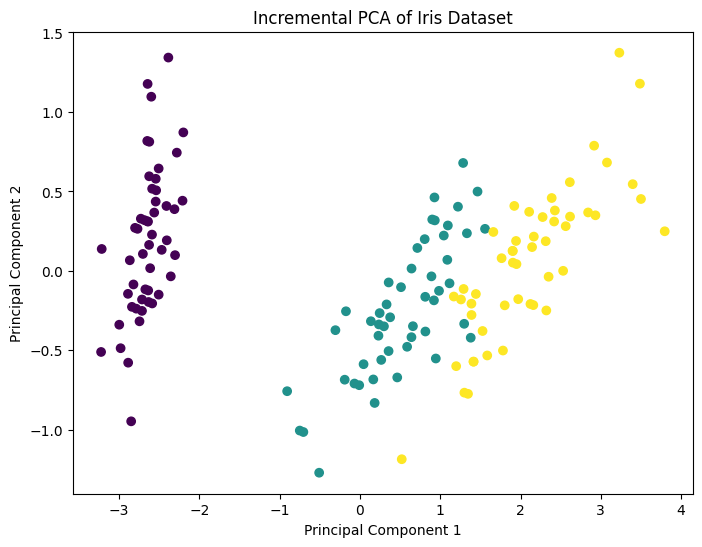

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import IncrementalPCA

# Load the Iris dataset
data = load_iris()
X = data.data
y = data.target

# Apply Incremental PCA to reduce the dataset to 2 dimensions
n_batches = 10
inc_pca = IncrementalPCA(n_components=2)
for X_batch in np.array_split(X, n_batches):
    inc_pca.partial_fit(X_batch)

X_reduced = inc_pca.transform(X)

# Plot the reduced dataset
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=y, cmap='viridis')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Incremental PCA of Iris Dataset')
#plt.legend(handles=scatter.legend_elements()[0], labels=data.target_names)
plt.show()